# 03 - LLM vs baseline

Compara, **na mesma amostra de 500 avaliações do teste** (estratificada, seed 42): baseline (TF-IDF + LR), LLM zero-shot e LLM few-shot.

Este notebook funciona sem e com cache de respostas do LLM (`data/cache_llm.jsonl`). Sem cache, as células do LLM são puladas.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from reviews import llm
from reviews.avaliacao import CLASSES_MATRIZ, comparar, contar_motivos, metricas, registros_da_amostra, resumo_llm
from reviews.baseline import treinar_baseline
from reviews.preparo import amostrar_teste, carregar_dados

sns.set_theme(style="whitegrid")
treino, teste = carregar_dados()
amostra = amostrar_teste(teste, 500)
print(len(amostra), "avaliações na amostra")
print(amostra["rotulo"].value_counts().to_dict())

500 avaliações na amostra
{'positivo': 355, 'negativo': 145}


## Baseline na amostra

In [2]:
modelo = treinar_baseline(treino["texto"], treino["rotulo"])
prev_baseline = modelo.predict(amostra["texto"])
m_base = metricas(amostra["rotulo"], prev_baseline)
print(f"Acurácia: {m_base['acuracia']:.3f} | F1 macro: {m_base['f1_macro']:.3f}")

Acurácia: 0.930 | F1 macro: 0.918


## Respostas do LLM (cache)

In [3]:
cache = llm.ler_cache()
registros = {modo: registros_da_amostra(amostra, modo, cache) for modo in ["zero-shot", "few-shot"]}
# modos com ao menos uma resposta da amostra no cache
modos_com_cache = [m for m, regs in registros.items() if any(r is not None for r in regs)]

if not modos_com_cache:
    print("Sem cache do LLM para esta amostra. Rode (gasta dinheiro, exige ANTHROPIC_API_KEY no .env):")
    print("  python -m reviews.llm --amostra 500 --modo zero-shot --confirmar")
    print("  python -m reviews.llm --amostra 500 --modo few-shot --confirmar")
    print("As células do LLM abaixo serão puladas.")
else:
    for modo in modos_com_cache:
        print(modo, resumo_llm(registros[modo]))

zero-shot {'custo': 0.041502800000000006, 'tempo': 682.5152368545532, 'falhas': 0, 'faltando': 0}
few-shot {'custo': 0.0620188, 'tempo': 654.7508211135864, 'falhas': 0, 'faltando': 0}


## Tabela comparativa

In [4]:
tabela = comparar(amostra, prev_baseline, registros)
tabela.round(3)

,acuracia,f1_macro,custo_US$,tempo_s,falhas,faltando
Baseline (TF-IDF + LR),0.930,0.918,0.000,NaN,0.0,0.0
LLM zero-shot,0.938,0.928,0.042,682.515,0.0,0.0
LLM few-shot,0.944,0.935,0.062,654.751,0.0,0.0


## Matrizes de confusão

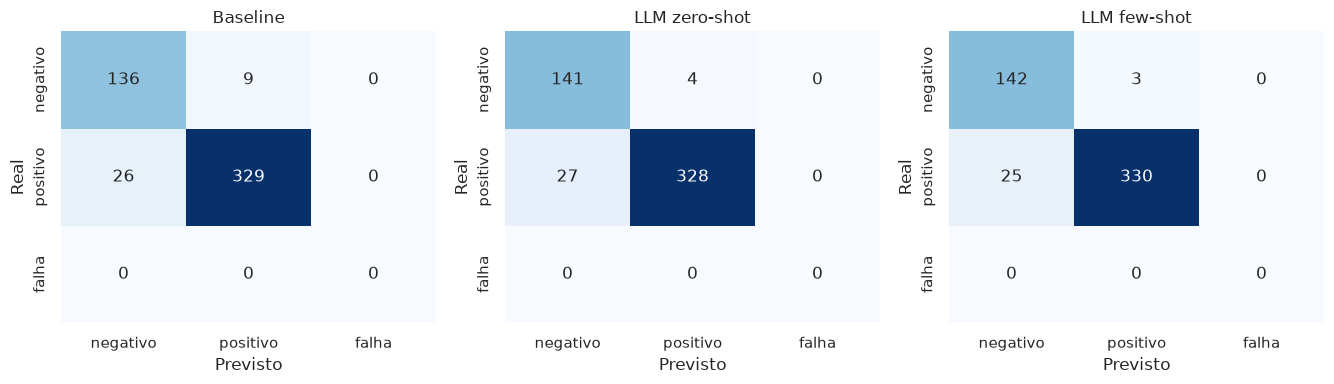

In [5]:
# só desenha modos completos (sem respostas faltando); falhas aparecem na coluna "falha"
modos_completos = [m for m in modos_com_cache if resumo_llm(registros[m])["faltando"] == 0]
previstos = {"Baseline": list(prev_baseline)}
for modo in modos_completos:
    previstos[f"LLM {modo}"] = [r["sentimento"] if r and r["ok"] else None for r in registros[modo]]

fig, eixos = plt.subplots(1, len(previstos), figsize=(4.5 * len(previstos), 4), squeeze=False)
for eixo, (nome, prev) in zip(eixos[0], previstos.items()):
    mat = metricas(amostra["rotulo"], prev)["matriz"]
    sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASSES_MATRIZ, yticklabels=CLASSES_MATRIZ, ax=eixo)
    eixo.set(title=nome, xlabel="Previsto", ylabel="Real")
plt.tight_layout()
plt.show()

## Motivos das avaliações negativas (segundo o LLM)

In [6]:
if not modos_com_cache:
    print("Pulado: sem respostas do LLM.")
else:
    motivos = {f"LLM {modo}": contar_motivos(registros[modo]) for modo in modos_com_cache}
    import pandas as pd
    display(pd.DataFrame(motivos))

,LLM zero-shot,LLM few-shot
entrega,105,99
produto,50,52
atendimento,1,3
cobrança,1,5
outro,11,8


## A diferença é real?

Os três métodos classificaram **as mesmas** 500 avaliações. Por isso, em vez de comparar só as
acurácias, dá para olhar caso a caso: em quantas avaliações um acertou e o outro errou. O teste de
McNemar pergunta se essa diferença poderia ter acontecido por acaso. Aqui ele é calculado à mão, com
o teste binomial exato.

In [7]:
from math import comb

reais = list(amostra["rotulo"])
previsoes = {
    "Baseline": list(prev_baseline),
    "zero-shot": [r["sentimento"] if r else None for r in registros["zero-shot"]],
    "few-shot": [r["sentimento"] if r else None for r in registros["few-shot"]],
}


def mcnemar(p1, p2):
    """Devolve (só o 1º acertou, só o 2º acertou, p-valor bilateral exato)."""
    so_1 = sum(a == r and b != r for a, b, r in zip(p1, p2, reais))
    so_2 = sum(a != r and b == r for a, b, r in zip(p1, p2, reais))
    n, k = so_1 + so_2, min(so_1, so_2)
    p_valor = min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) / 2**n)
    return so_1, so_2, round(p_valor, 3)


for a, b in [("Baseline", "zero-shot"), ("Baseline", "few-shot"), ("zero-shot", "few-shot")]:
    print(f"{a} x {b}: só o 1º acertou, só o 2º acertou, p-valor = {mcnemar(previsoes[a], previsoes[b])}")

errados_pelos_tres = [i for i, r in enumerate(reais)
                      if all(previsoes[m][i] != r for m in previsoes)]
print(f"\nErrados pelos três: {len(errados_pelos_tres)}")
amostra.iloc[errados_pelos_tres][["rotulo", "texto"]].head(8)

Baseline x zero-shot: só o 1º acertou, só o 2º acertou, p-valor = (11, 15, 0.557)
Baseline x few-shot: só o 1º acertou, só o 2º acertou, p-valor = (9, 16, 0.23)
zero-shot x few-shot: só o 1º acertou, só o 2º acertou, p-valor = (2, 5, 0.453)

Errados pelos três: 18


,rotulo,texto
35,positivo,só recebi o produto após intervenção do procon...
56,positivo,"recebi, a bolsa é diferente mas gostei estava ..."
57,positivo,"só deixou a desejar na entrega, quem foi entre..."
58,negativo,ótimo site para comprar muito confiável
100,positivo,"na decisão do produto,diz que pode colocar em ..."
108,positivo,comprei o produto como original e veio um comp...
112,positivo,"no entanto, ainda falta o outro produto do mes..."
152,positivo,o pedido foi feito na cor pérola e veio branca


## Conclusão

- **Sentimento:** o LLM ficou 1 a 1,5 ponto acima do baseline em acurácia, mas o teste de McNemar mostra
  que a diferença não é significativa (p-valores entre 0,23 e 0,56). Com 500 avaliações, os três empatam.
- **Os erros são quase os mesmos:** as avaliações erradas pelos três são, em geral, textos que contradizem
  a nota (reclamação com nota 5, elogio com nota 1). O limite está no rótulo, não no modelo.
- **Custo e tempo:** o baseline treina em menos de um segundo e não custa nada; o LLM levou cerca de 11
  minutos e US$ 0,04 (zero-shot) ou US$ 0,06 (few-shot) para 500 avaliações. Os exemplos do few-shot
  encarecem o prompt em cerca de 65% sem ganho estatisticamente claro.
- **Onde o LLM vale a pena:** classificar o *motivo* das reclamações sem nenhum dado rotulado. Cerca de dois
  terços das avaliações negativas são sobre entrega.

**Recomendação:** modelo clássico para o sentimento e o LLM só nas avaliações negativas, para descobrir o motivo.